<a href="https://colab.research.google.com/github/yuhang-um/data-science-toolkit/blob/main/Tutorial03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h2>Tutorial 3</h2>

<h3>1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it </h3>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
df=pd.read_csv("/content/drive/MyDrive/supermarket.csv")

In [6]:
print("First five rows:\n")
df.head()

First five rows:



,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


<h3>Conclusion for question 1: </h3>
<p>The dataset (supermarket.csv) is successfully found from kaggle and mounted in Google Colab. </p>
<p>The first five rows of data is successfully visualized from csv file. </p>

<h3>2. Evaluate if the data is good or not. Does it have enough samples? </h3>

In [17]:
print("number of rows and columns: ", df.shape)
print("Number of duplicated rows: ", df.duplicated().sum())

number of rows and columns:  (9800, 18)
Number of duplicated rows:  0


<h3>Conclusion for question2: </h3>
The datasets is generally useful for exploratory data analysis because it contains a large number of records a various type of customer, product and sales information.
<p> df.shape shows that the file contain 18 columns and 9800 rows, which is suitable enough for EDA. </p>
<p>df.duplicated().sum() shows that every row is unique identified.

<h3>3. How many features does it have? Is it enough? </h3>




In [28]:
#features are the information that help to answer a question
print("All columns:")
print(df.columns.tolist()) #tolist() : return a single column into a list form.
columns_count=len(df.columns)
print("Number of columns: ", columns_count)
print("Possible input columns (excluding Row ID): ", columns_count-1)

All columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']
Number of columns:  18
Possible input columns (excluding Row ID):  17


<h3> Conclusion for question 3: </h3>
<p>The dataset has 18 columns in total. </p>
<p>Row ID is excluded because it is only an indentifier to each row, does not bring any information or meaningful feature for analyzing data patterns. </p>

<h3>4. How many samples/observation does it have? Is it enough?</h3>

In [47]:
print("Number of observations: ", df.shape[0])

Number of observations: 


9800

<h3>Conclusion for question 4: </3>
<p>There are 9800 observations in this datasets. Hence, it is enough to calculate statistical summary of all numerical columns and even construct data visualizations. </p>

<h3>5. What are the datatypes does the dataset consist of?</3>

In [30]:
print(df.dtypes)

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
dtype: object


<h3> Conclusion for question 5: </h3>
<p> There are 3 types of data in this dataset: </p>
<p> - "object" to represent text</p>
<p> - "int64" to represent integer numbers</p>
<p> - "float64" to represent floating point numbers</p>

<h3> 6. How many columns have null values? If yes, which column, which rows </h3>

In [51]:
missing=df.isnull().sum()  #count missing value in each column
print("missing values in each column: ")
print(missing)
print("\nColumns with missing values: ")
print(missing[missing>0])  #display column that contain at least 1 missing value
print("\nNumber of columns with missing values: ")
print((missing>0).sum())
print("\nRows that contain missing value: ")
rows_null=df.isnull().any(axis=1) # any(): check a collection of truefalse value ; axis=1 : rows
df[rows_null]

missing values in each column: 
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

Columns with missing values: 
Postal Code    11
dtype: int64

Number of columns with missing values: 
1

Rows that contain missing value: 


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
2234,2235,CA-2018-104066,05/12/2018,10/12/2018,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03
5274,5275,CA-2016-162887,07/11/2016,09/11/2016,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,Vermont,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20
8798,8799,US-2017-150140,06/04/2017,10/04/2017,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,Vermont,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75
9146,9147,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98
9147,9148,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04
9148,9149,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29
9386,9387,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92
9387,9388,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28
9388,9389,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94
9389,9390,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04


<h3> Conclusion for question 6</h3>
<p>There are one column (Postal Code) contain null values, and there are 11 rows contain null values in this column. </p>
<p>Rows[2235, 5275, 8799, 9147, 9148, 9149, 9387, 9389, 9390, 9742] contain null values. </p>


<h3> 7. Which column is the feature, which is the target output? </h3>

In [64]:
target="Sales"
features=df.drop(columns=["Sales", "Row ID", "Order ID"])

print("Target: ", target)
print("Features: ", features.columns.tolist())
print("Number of possible features: ", features.shape[1])
df[target]


Target:  Sales
Features:  ['Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']
Number of possible features:  15


,Sales
0,261.9600
1,731.9400
2,14.6200
3,957.5775
4,22.3680
...,...
9795,3.7980
9796,10.3680
9797,235.1880
9798,26.3760


<h3> Conclusion for question 7: </h3>
Assume my target the sales prediction for customer preferences, hence the features that are litte useful or useless are [Sales, Row ID, Order ID]. "Sales" is removed because it is the answer we want to predict. "Row ID" and "Order ID" are excluded because they are indentifiers instead of giving meaningful sales prediction. However, "Customer ID" and "Product ID" are included because we can use them to predict customer preferences based on their purchasing history.

<h3> 8. Does it have missing values? If yes, which column, which row. </h3>

In [65]:
missing=df.isnull().sum()  #count missing value in each column
print("missing values in each column: ")
print(missing)
print("\nColumns with missing values: ")
print(missing[missing>0])  #display column that contain at least 1 missing value
print("\nNumber of columns with missing values: ")
print((missing>0).sum())
print("\nRows that contain missing value: ")
rows_null=df.isnull().any(axis=1) # any(): check a collection of truefalse value ; axis=1 : rows
df[rows_null]

missing values in each column: 
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

Columns with missing values: 
Postal Code    11
dtype: int64

Number of columns with missing values: 
1

Rows that contain missing value: 


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
2234,2235,CA-2018-104066,05/12/2018,10/12/2018,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03
5274,5275,CA-2016-162887,07/11/2016,09/11/2016,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,Vermont,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20
8798,8799,US-2017-150140,06/04/2017,10/04/2017,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,Vermont,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75
9146,9147,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98
9147,9148,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04
9148,9149,US-2017-165505,23/01/2017,27/01/2017,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29
9386,9387,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92
9387,9388,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28
9388,9389,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94
9389,9390,US-2018-127292,19/01/2018,23/01/2018,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04


<h3> Conclusion for question 8: </h3>
<p>There are one column (Postal Code) contain null values, and there are 11 rows contain null values in this column. </p>
<p>Rows[2235, 5275, 8799, 9147, 9148, 9149, 9387, 9389, 9390, 9742] contain null values. </p>


<h3> 9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking? </h3>

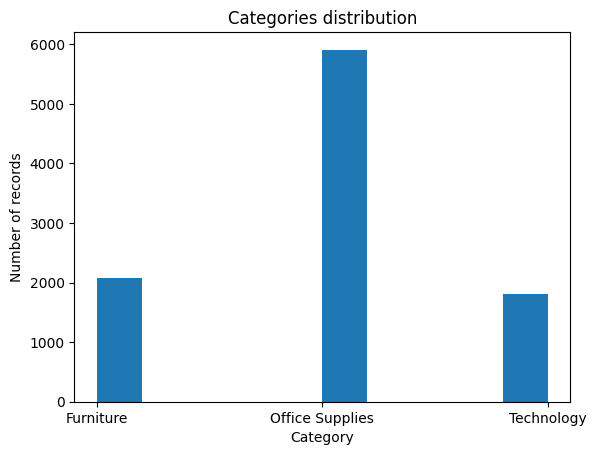

In [70]:
# we can construct data visualization, such as visualizing each category to view their population easily
import matplotlib.pyplot as plt
species=df['Category']
plt.title("Categories distribution")
plt.hist(species)
plt.xlabel("Category")
plt.ylabel("Number of records")
plt.show()

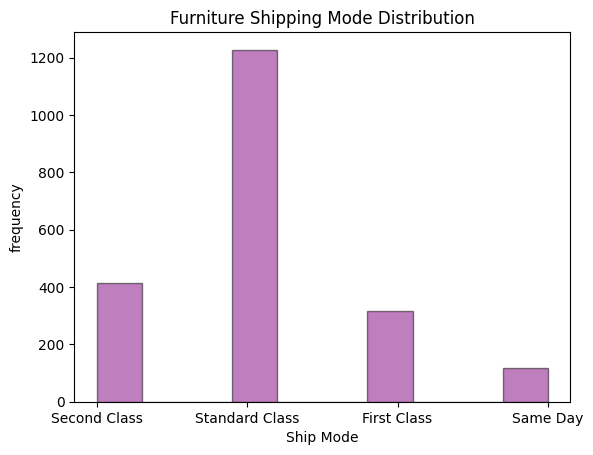

In [99]:
# we can even make it more complex by visualizing the shipping mode (Second Class, Standard Class, First Class, Same Day) distribution for each category

#seperate the data by category
furniture=df.loc[df["Category"]=="Furniture"]
office_supplies=df.loc[df["Category"]=="Office Supplies"]
technology=df.loc[df["Category"]=="Technology"]

#retrieve sales data from each category
furniture_shipping=furniture["Ship Mode"]
office_supplies_shipping=office_supplies["Ship Mode"]
technology_shipping=technology["Ship Mode"]

#visualize the shipping mode distribution for each category
plt.hist(furniture_shipping, color='purple', alpha=0.5, edgecolor='black')

plt.title('Furniture Shipping Mode Distribution')
plt.xlabel('Ship Mode')
plt.ylabel('frequency')
plt.show()

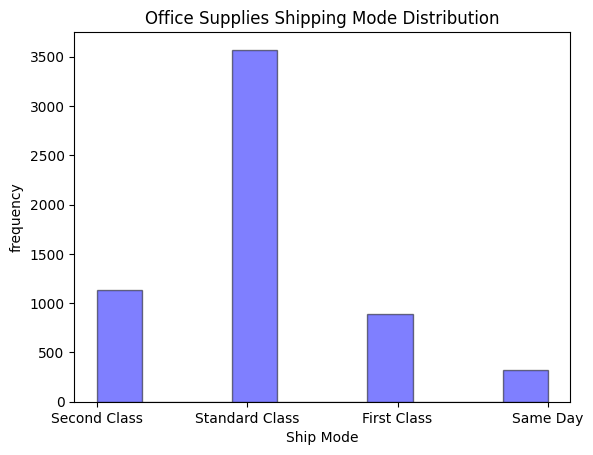

In [100]:
plt.hist(office_supplies_shipping, color='blue', alpha=0.5, edgecolor='black')

plt.title('Office Supplies Shipping Mode Distribution')
plt.xlabel('Ship Mode')
plt.ylabel('frequency')
plt.show()

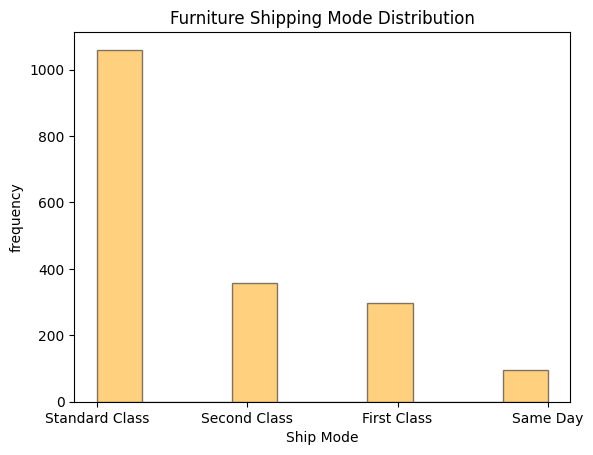

In [101]:
plt.hist(technology_shipping, color='orange', alpha=0.5, edgecolor='black',)

plt.title('Furniture Shipping Mode Distribution')
plt.xlabel('Ship Mode')
plt.ylabel('frequency')
plt.show()

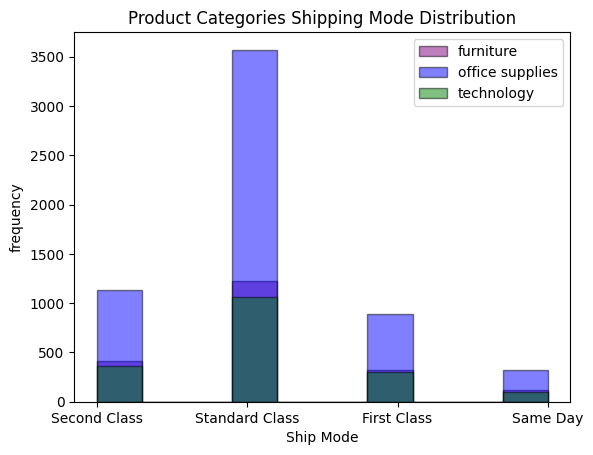

In [103]:
#combination of three graphs
plt.hist(furniture_shipping, color='purple', alpha=0.5, edgecolor='black', label='furniture')
plt.hist(office_supplies_shipping, color='blue', alpha=0.5, edgecolor='black', label='office supplies')
plt.hist(technology_shipping, color='green', alpha=0.5, edgecolor='black', label='technology')
plt.title('Product Categories Shipping Mode Distribution')
plt.xlabel('Ship Mode')
plt.ylabel('frequency')
plt.legend()
plt.show()